In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('/content/flood_risk_dataset_india (3).csv')

# Standardise columns to match downstream cell expectations (lower case, replace spaces and symbols with underscores)
df.columns = df.columns.str.lower() \
                      .str.replace(' ', '_') \
                      .str.replace('(', '_') \
                      .str.replace(')', '_') \
                      .str.replace('/', '_') \
                      .str.replace('°', '') \
                      .str.replace('%', '')

print("Dataset loaded and columns standardised successfully!")
print("Rows and Columns:", df.shape)
print("\nStandardised Columns:")
print(df.columns.tolist())
display(df.head())

Dataset loaded and columns standardised successfully!
Rows and Columns: (10000, 14)

Standardised Columns:
['latitude', 'longitude', 'rainfall__mm_', 'temperature__c_', 'humidity___', 'river_discharge__m³_s_', 'water_level__m_', 'elevation__m_', 'land_cover', 'soil_type', 'population_density', 'infrastructure', 'historical_floods', 'flood_occurred']


,latitude,longitude,rainfall__mm_,temperature__c_,humidity___,river_discharge__m³_s_,water_level__m_,elevation__m_,land_cover,soil_type,population_density,infrastructure,historical_floods,flood_occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465433,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


## Average Rainfall vs Flood Occurrence


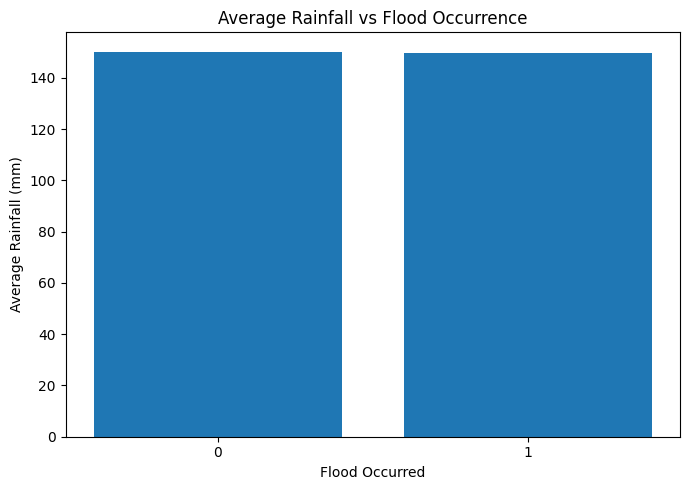

In [53]:
rainfall_flood = df.groupby('flood_occurred')['rainfall__mm_'].mean()
plt.figure(figsize=(7,5))
plt.bar(rainfall_flood.index.astype(str), rainfall_flood.values)
plt.xlabel('Flood Occurred')
plt.ylabel('Average Rainfall (mm)')
plt.title('Average Rainfall vs Flood Occurrence')
plt.tight_layout()
plt.show()

## Average Water Level vs Flood Occurrence


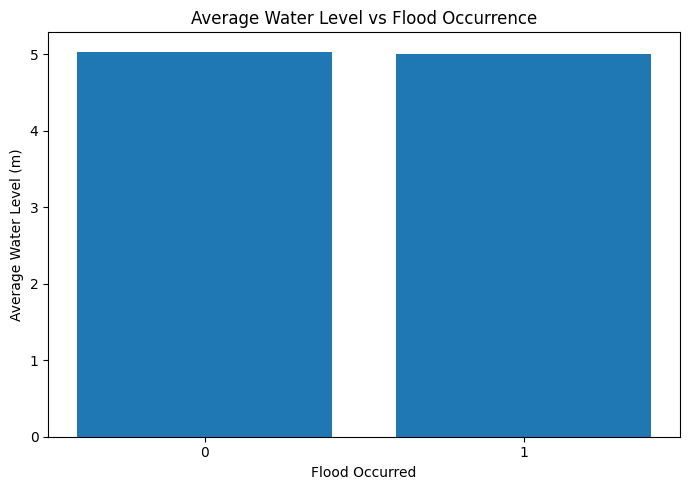

In [54]:
water_flood = df.groupby('flood_occurred')['water_level__m_'].mean()
plt.figure(figsize=(7,5))
plt.bar(water_flood.index.astype(str), water_flood.values)
plt.xlabel('Flood Occurred')
plt.ylabel('Average Water Level (m)')
plt.title('Average Water Level vs Flood Occurrence')
plt.tight_layout()
plt.show()

## Average River Discharge vs Flood Occurrence


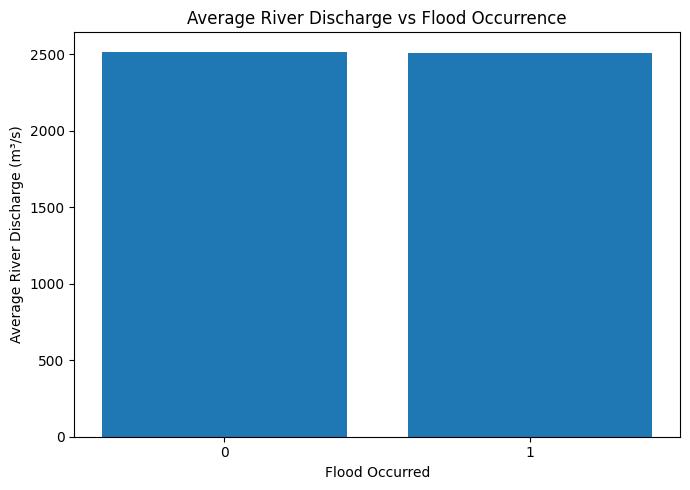

In [55]:
discharge_flood = df.groupby('flood_occurred')['river_discharge__m³_s_'].mean()
plt.figure(figsize=(7,5))
plt.bar(discharge_flood.index.astype(str), discharge_flood.values)
plt.xlabel('Flood Occurred')
plt.ylabel('Average River Discharge (m³/s)')
plt.title('Average River Discharge vs Flood Occurrence')
plt.tight_layout()
plt.show()

## Temperature vs Humidity


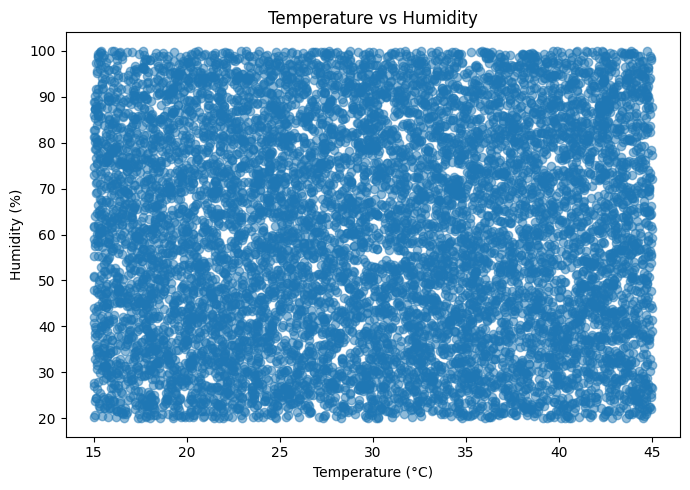

In [56]:
plt.figure(figsize=(7,5))
plt.scatter(df['temperature__c_'], df['humidity___'], alpha=0.5)
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs Humidity')
plt.tight_layout()
plt.show()

## Flood Occurrence (0 vs 1)


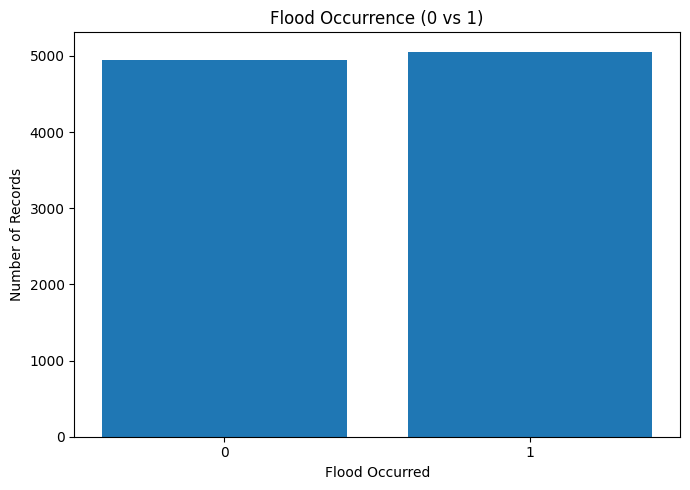

In [57]:
flood_count = df['flood_occurred'].value_counts().sort_index()
plt.figure(figsize=(7,5))
plt.bar(flood_count.index.astype(str), flood_count.values)
plt.xlabel('Flood Occurred')
plt.ylabel('Number of Records')
plt.title('Flood Occurrence (0 vs 1)')
plt.tight_layout()
plt.show()

## Land Cover vs Flood Occurrence


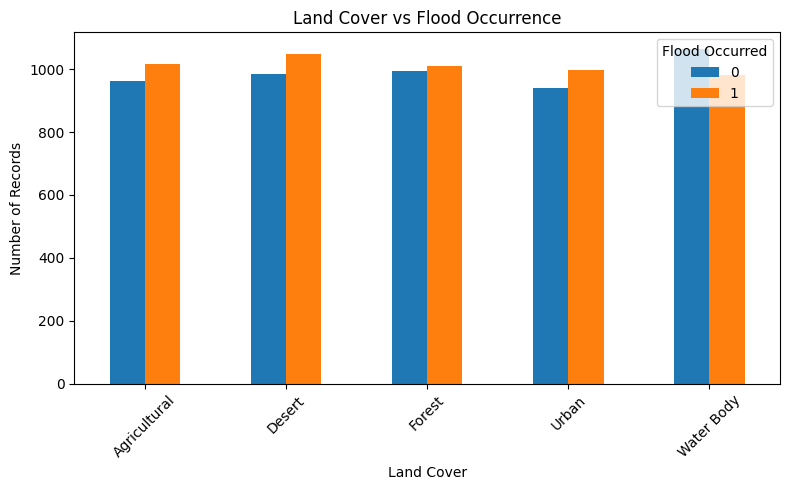

In [58]:
land_flood = pd.crosstab(df['land_cover'], df['flood_occurred'])
land_flood.plot(kind='bar', figsize=(8,5))
plt.xlabel('Land Cover')
plt.ylabel('Number of Records')
plt.title('Land Cover vs Flood Occurrence')
plt.xticks(rotation=45)
plt.legend(title='Flood Occurred')
plt.tight_layout()
plt.show()

## Soil Type vs Flood Occurrence


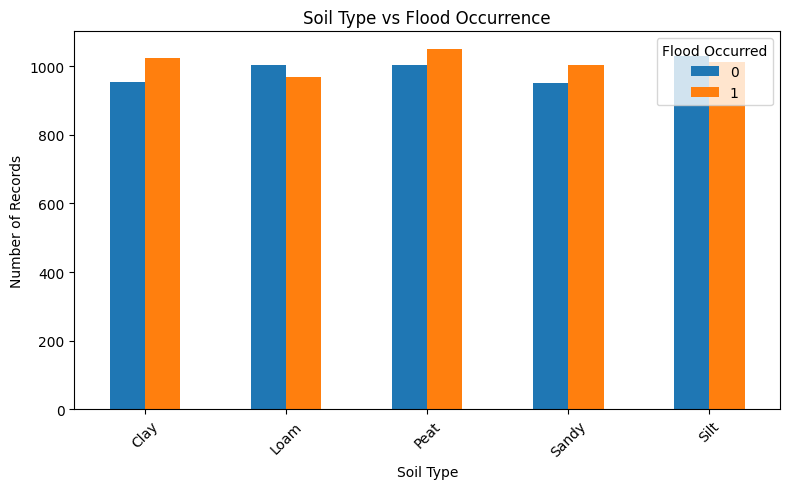

In [59]:
soil_flood = pd.crosstab(df['soil_type'], df['flood_occurred'])
soil_flood.plot(kind='bar', figsize=(8,5))
plt.xlabel('Soil Type')
plt.ylabel('Number of Records')
plt.title('Soil Type vs Flood Occurrence')
plt.xticks(rotation=45)
plt.legend(title='Flood Occurred')
plt.tight_layout()
plt.show()

## Population Density vs Flood Occurrence


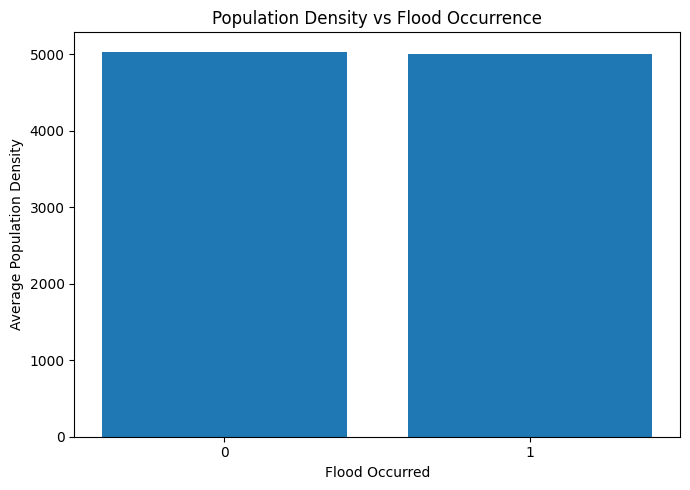

In [60]:
population_flood = df.groupby('flood_occurred')['population_density'].mean()
plt.figure(figsize=(7,5))
plt.bar(population_flood.index.astype(str), population_flood.values)
plt.xlabel('Flood Occurred')
plt.ylabel('Average Population Density')
plt.title('Population Density vs Flood Occurrence')
plt.tight_layout()
plt.show()

## Historical Floods vs Flood Occurrence


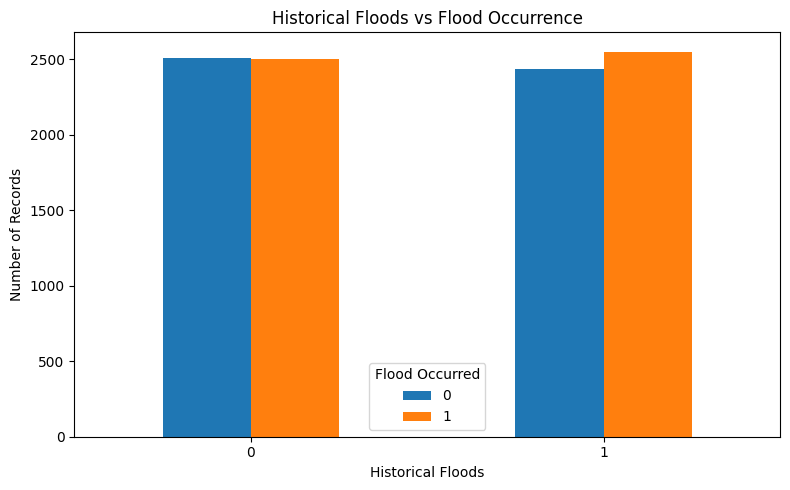

In [61]:
historical_flood = pd.crosstab(df['historical_floods'], df['flood_occurred'])
historical_flood.plot(kind='bar', figsize=(8,5))
plt.xlabel('Historical Floods')
plt.ylabel('Number of Records')
plt.title('Historical Floods vs Flood Occurrence')
plt.xticks(rotation=0)
plt.legend(title='Flood Occurred')
plt.tight_layout()
plt.show()

## Rainfall vs Water Level


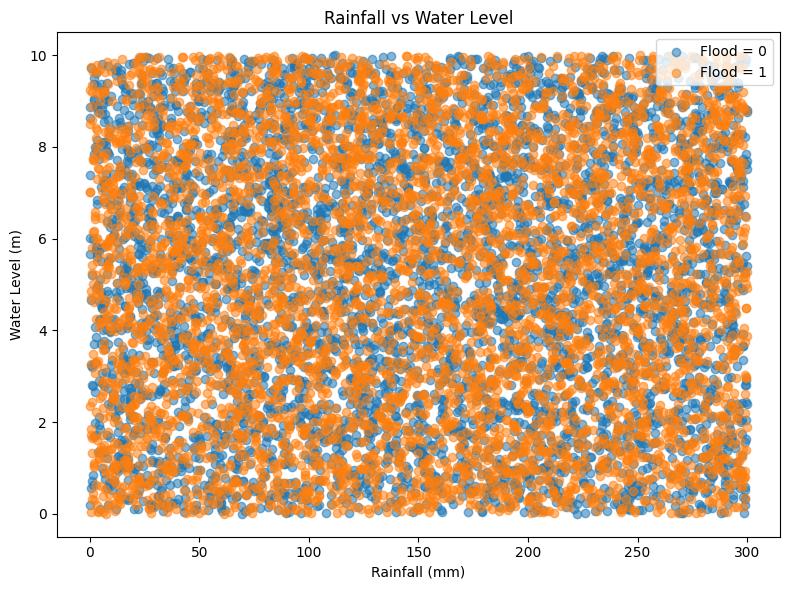

In [62]:
plt.figure(figsize=(8,6))
for flood_value, group in df.groupby('flood_occurred'):
    plt.scatter(group['rainfall__mm_'], group['water_level__m_'],
                alpha=0.55, label=f'Flood = {flood_value}')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Water Level (m)')
plt.title('Rainfall vs Water Level')
plt.legend()
plt.tight_layout()
plt.show()

## Rainfall vs River Discharge


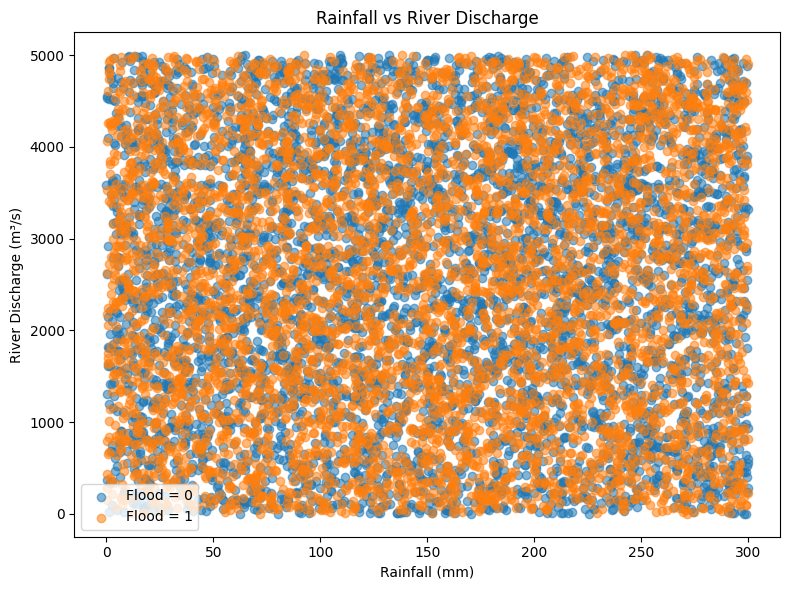

In [63]:
plt.figure(figsize=(8,6))
for flood_value, group in df.groupby('flood_occurred'):
    plt.scatter(group['rainfall__mm_'], group['river_discharge__m³_s_'],
                alpha=0.55, label=f'Flood = {flood_value}')
plt.xlabel('Rainfall (mm)')
plt.ylabel('River Discharge (m³/s)')
plt.title('Rainfall vs River Discharge')
plt.legend()
plt.tight_layout()
plt.show()

## Rainfall Distribution


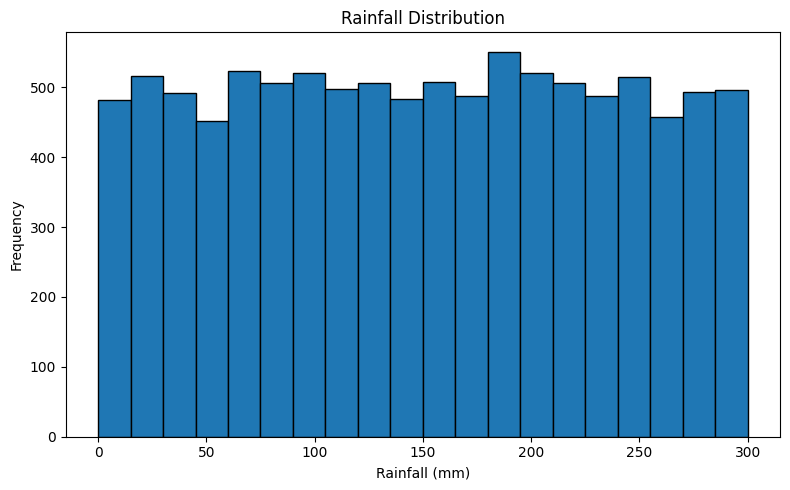

In [64]:
plt.figure(figsize=(8,5))
plt.hist(df['rainfall__mm_'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Frequency')
plt.title('Rainfall Distribution')
plt.tight_layout()
plt.show()

## Rainfall by Flood Occurrence – Box Plot


/tmp/ipykernel_5041/1308559785.py:7: MatplotlibDeprecationWarning:

The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.



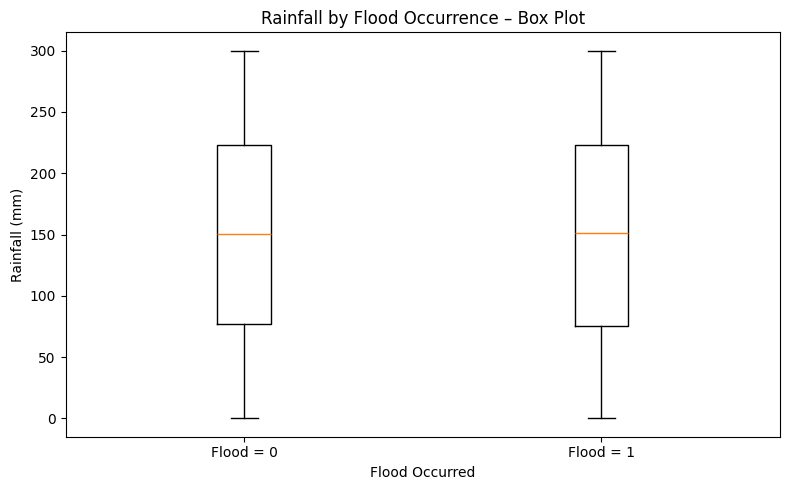

In [65]:
box_values = [
    df.loc[df['flood_occurred'] == v, 'rainfall__mm_'].dropna()
    for v in sorted(df['flood_occurred'].dropna().unique())
]
box_labels = [f'Flood = {v}' for v in sorted(df['flood_occurred'].dropna().unique())]
plt.figure(figsize=(8,5))
plt.boxplot(box_values, labels=box_labels)
plt.xlabel('Flood Occurred')
plt.ylabel('Rainfall (mm)')
plt.title('Rainfall by Flood Occurrence – Box Plot')
plt.tight_layout()
plt.show()

## Correlation Heatmap


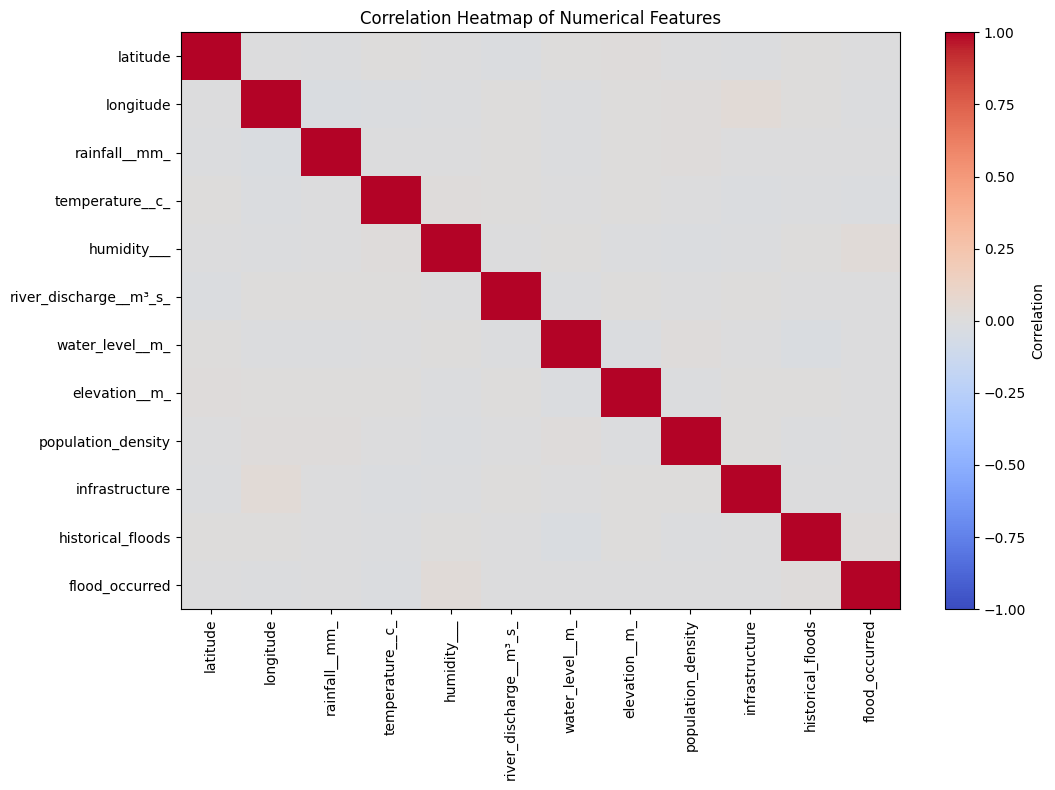

In [45]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(corr, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
ax.set_title('Correlation Heatmap of Numerical Features')
fig.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

## Flood vs Non-Flood Records – Pie Chart


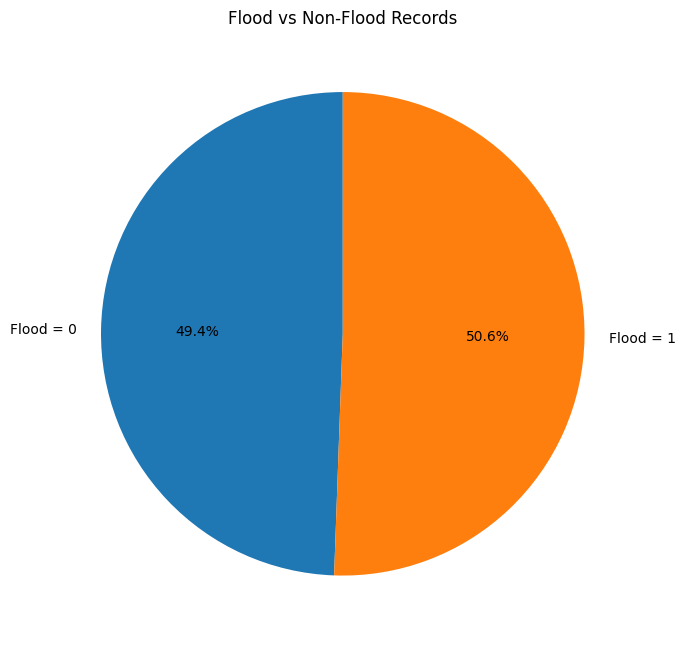

In [46]:
flood_counts = df['flood_occurred'].value_counts().sort_index()
plt.figure(figsize=(7,7))
plt.pie(flood_counts.values,
        labels=[f'Flood = {v}' for v in flood_counts.index],
        autopct='%1.1f%%', startangle=90)
plt.title('Flood vs Non-Flood Records')
plt.tight_layout()
plt.show()

## Rainfall by Flood Occurrence – Violin Plot


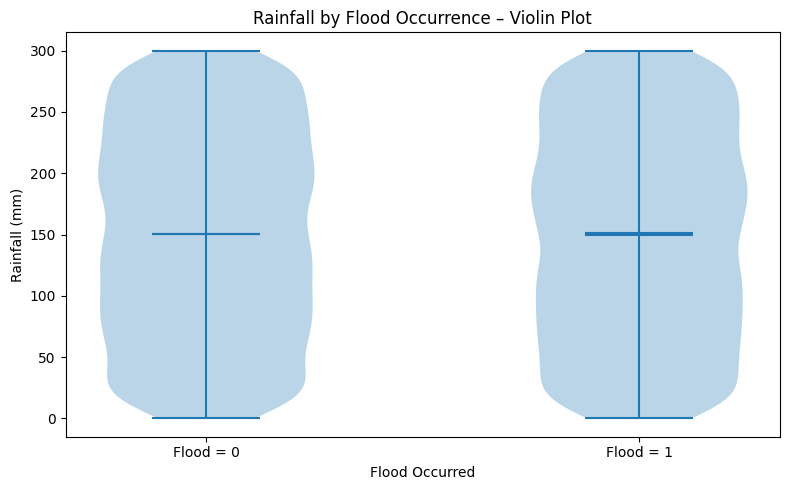

In [47]:
violin_values = [
    df.loc[df['flood_occurred'] == v, 'rainfall__mm_'].dropna()
    for v in sorted(df['flood_occurred'].dropna().unique())
]
violin_labels = [f'Flood = {v}' for v in sorted(df['flood_occurred'].dropna().unique())]
plt.figure(figsize=(8,5))
plt.violinplot(violin_values, showmeans=True, showmedians=True)
plt.xticks(range(1, len(violin_labels)+1), violin_labels)
plt.xlabel('Flood Occurred')
plt.ylabel('Rainfall (mm)')
plt.title('Rainfall by Flood Occurrence – Violin Plot')
plt.tight_layout()
plt.show()

## Treemap – Land Cover and Soil Type


In [48]:
# Install Plotly if it is not already available in Google Colab
%pip -q install plotly

import plotly.express as px

treemap_data = (
    df.groupby(['land_cover', 'soil_type'], dropna=False)
      .size()
      .reset_index(name='record_count')
)
treemap_data['land_cover'] = treemap_data['land_cover'].fillna('Unknown')
treemap_data['soil_type'] = treemap_data['soil_type'].fillna('Unknown')

fig = px.treemap(
    treemap_data,
    path=['land_cover', 'soil_type'],
    values='record_count',
    color='record_count',
    title='Land Cover and Soil Type Distribution'
)
fig.show()

## Flood Occurrence by Land Cover – Stacked Bar Chart


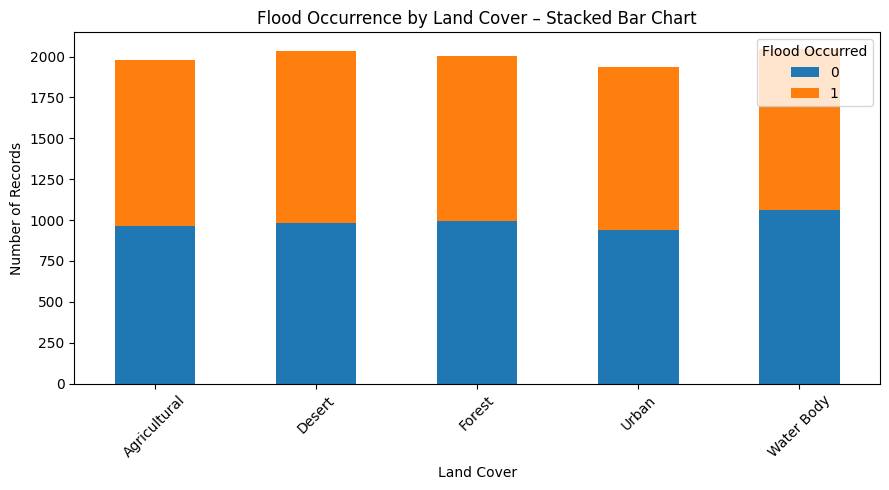

In [49]:
land_flood_percent = pd.crosstab(df['land_cover'], df['flood_occurred'])
land_flood_percent.plot(kind='bar', stacked=True, figsize=(9,5))
plt.xlabel('Land Cover')
plt.ylabel('Number of Records')
plt.title('Flood Occurrence by Land Cover – Stacked Bar Chart')
plt.xticks(rotation=45)
plt.legend(title='Flood Occurred')
plt.tight_layout()
plt.show()

## Water Level Distribution


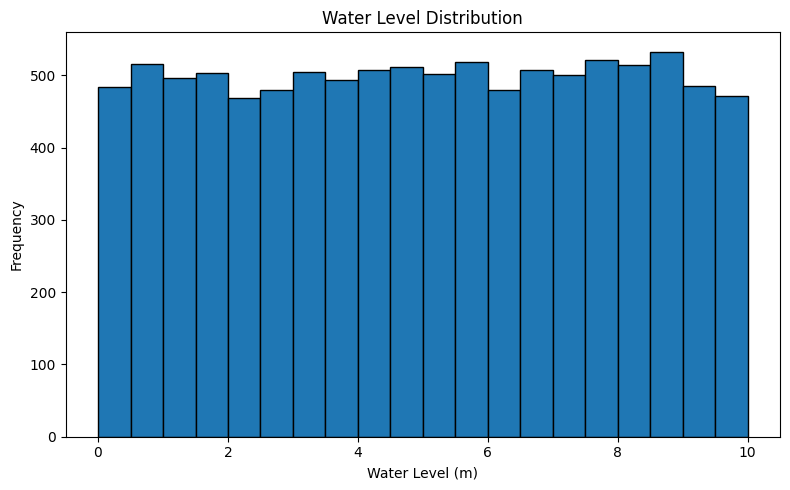

In [50]:
plt.figure(figsize=(8,5))
plt.hist(df['water_level__m_'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Water Level (m)')
plt.ylabel('Frequency')
plt.title('Water Level Distribution')
plt.tight_layout()
plt.show()

## River Discharge Distribution


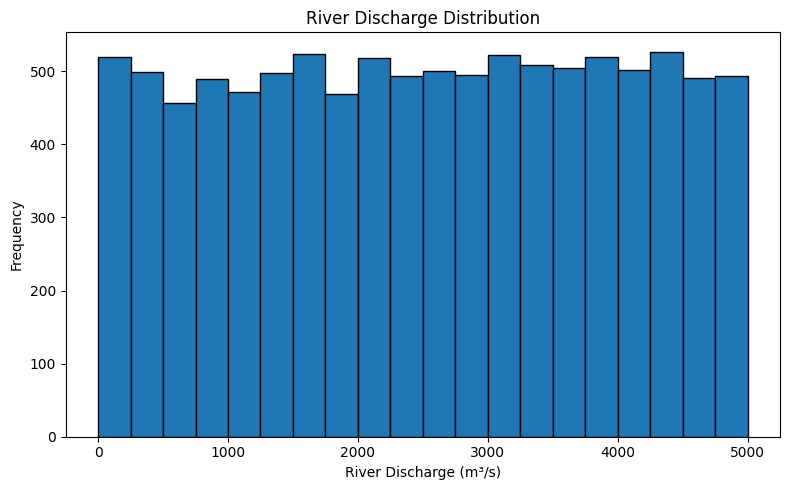

In [51]:
plt.figure(figsize=(8,5))
plt.hist(df['river_discharge__m³_s_'].dropna(), bins=20, edgecolor='black')
plt.xlabel('River Discharge (m³/s)')
plt.ylabel('Frequency')
plt.title('River Discharge Distribution')
plt.tight_layout()
plt.show()